# IN1002B: DESARROLLO DE PROYECTOS DE ANÁLISIS DE DATOS
## Reto – Capítulo 2: Preparación de la Base de Datos (Airbnb CDMX – `listings.csv`)

## Contenido

1. Leer archivo
1. Preprocesar los datos (metodología de preparación)
    1. Revisión de relevancia de variables
    1. Revisión y corrección de datos perdidos
    1. Detección y corrección de inconsistencias
    1. Tratamiento de variables numéricas (valores atípicos)
    1. Tratamiento de variables categóricas
    1. Transformación de datos (codificación)
1. Análisis y Visualización
1. Validación de la base de datos final
1. Archivo final de la Base de Datos y conclusiones

In [1]:
# importamos librerías
import warnings
warnings.filterwarnings("ignore")

In [2]:
import numpy as np # librería para poder usar arreglos
import pandas as pd # librería para poder usar DataFrames (tablas)
import matplotlib.pyplot as plt # to plot
import seaborn as sns # to plot
import random
import string
from scipy import stats # estadística (asimetría, pruebas)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
random.seed(42) # colores reproducibles

## 1. Leer archivo

In [3]:
dataSet = pd.read_csv("listings.csv", header=0)

In [4]:
print(dataSet.head())
print("")
print(dataSet.info())
print("")
print(dataSet.isnull().sum())
print("")
print(round(dataSet.describe(), 2).T)

      id                                               name  host_id      host_profile_id host_name  neighbourhood_group          neighbourhood  latitude  longitude        room_type    price  \
0  35797                                              Villa   153786  1462510079499349160      Dici                  NaN  Cuajimalpa de Morelos  19.38283  -99.27178     Private room   8874.0   
1  44616                                       Condesa Haus   196253  1462512367669904597   Condesa                  NaN             Cuauhtémoc  19.41162  -99.17794  Entire home/apt  21950.0   
2  56074               Great space in historical San Rafael   265650  1462514125461160774     Maris                  NaN             Cuauhtémoc  19.43977  -99.15605  Entire home/apt    605.0   
3  66055  Private Room+Bath 10 min Walk to World Cup Sta...   323211  1462515703523909330      Aldo                  NaN               Coyoacán  19.31202  -99.14420     Private room   3095.0   
4  67703                  2 be

**Descripción inicial:** la base contiene **30,468 anuncios (registros) y 19 variables** de alojamientos de Airbnb en la Ciudad de México. Hay variables de identificación (`id`, `host_id`, `host_profile_id`), texto libre (`name`, `host_name`), ubicación (`neighbourhood`, `latitude`, `longitude`), tipo de alojamiento (`room_type`), precio por noche (`price`), condiciones de reserva (`minimum_nights`, `availability_365`) y actividad/reseñas (`number_of_reviews`, `last_review`, `reviews_per_month`, `number_of_reviews_ltm`, `calculated_host_listings_count`).

## 2. Preprocesar los datos

### Metodología de preparación

Se sigue una metodología secuencial; cada paso se documenta con su **criterio de decisión** y se valida con estadística descriptiva y gráficas:

| Paso | Actividad | Criterio principal |
| :-: | :-- | :-- |
| 1 | Revisión de relevancia de variables | Se eliminan variables 100% vacías, identificadores técnicos y texto libre sin valor estadístico |
| 2 | Datos perdidos | Se distingue entre nulos **estructurales** (se imputan con su valor lógico) y nulos en la **variable objetivo** (se eliminan) |
| 3 | Inconsistencias | Duplicados, rangos imposibles, reglas lógicas entre columnas y estandarización de texto |
| 4 | Variables numéricas | Detección de atípicos con RIC (Tukey) sobre `log(price)` por la fuerte asimetría |
| 5 | Variables categóricas | Frecuencias, consistencia de categorías y relación con el precio |
| 6 | Transformación | Nuevas variables (`log_price`, `dias_desde_ultima_resena`, `tipo_estancia`) y codificación *one-hot* |
| 7 | Validación | Completitud, consistencia de rangos y representatividad (proporciones antes vs. después) |

### 2.1 Revisión de relevancia de variables

In [5]:
diccionario = pd.DataFrame({
    "Tipo": dataSet.dtypes.astype(str),
    "Nulos": dataSet.isnull().sum(),
    "% Nulos": round(dataSet.isnull().mean() * 100, 2),
    "Valores únicos": dataSet.nunique()
})
print(diccionario.to_string())

                                   Tipo  Nulos  % Nulos  Valores únicos
id                                int64      0     0.00           30468
name                             object      0     0.00           29037
host_id                           int64      0     0.00           13381
host_profile_id                   int64      0     0.00           13381
host_name                        object      0     0.00            4883
neighbourhood_group             float64  30468   100.00               0
neighbourhood                    object      0     0.00              16
latitude                        float64      0     0.00           17564
longitude                       float64      0     0.00           16188
room_type                        object      0     0.00               4
price                           float64   2108     6.92            5262
minimum_nights                  float64      1     0.00              60
number_of_reviews                 int64      0     0.00         

In [6]:
# Variables que no aportan al análisis estadístico
cols_eliminar = ["neighbourhood_group", # 100% nulos
                 "license",             # 100% nulos
                 "host_profile_id",     # identificador técnico del perfil
                 "name",                # texto libre (título del anuncio)
                 "host_name"]           # texto libre / dato personal del anfitrión

df = dataSet.copy()
df = df.drop(columns=cols_eliminar)
print("Columnas eliminadas:", cols_eliminar)
print("Dimensiones:", dataSet.shape, "->", df.shape)
print("")
print(df.columns.tolist())

Columnas eliminadas: ['neighbourhood_group', 'license', 'host_profile_id', 'name', 'host_name']
Dimensiones: (30468, 19) -> (30468, 14)

['id', 'host_id', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm']

**Decisión:** se eliminaron `neighbourhood_group` y `license` porque están **100% vacías** (no contienen información); `host_profile_id` porque es un identificador técnico redundante con `host_id`; y `name` / `host_name` porque son texto libre (casi un valor distinto por registro) sin valor para el análisis estadístico y, en el caso del nombre del anfitrión, es un dato personal. Se conservan `id` y `host_id` únicamente como llaves de identificación (no se usan como variables de análisis).

### 2.2 Revisión y corrección de datos perdidos

                   Nulos  % Nulos
price               2108     6.92
minimum_nights         1     0.00
last_review         4083    13.40
reviews_per_month   4083    13.40

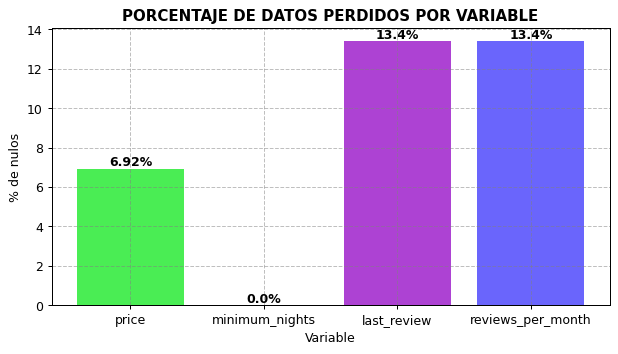

In [7]:
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]
pct_nulos = round(nulos / len(df) * 100, 2)
print(pd.DataFrame({"Nulos": nulos, "% Nulos": pct_nulos}))

plt.figure(figsize=(8, 4))
patches = plt.bar(pct_nulos.index, pct_nulos.values)
for j in range(len(patches)):
    patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
    plt.text(patches[j].get_x() + patches[j].get_width() / 2, patches[j].get_height(),
             str(pct_nulos.values[j]) + "%", ha='center', va='bottom', fontweight='bold')
plt.grid(color='grey', linestyle='dashed', alpha=0.5)
plt.title('PORCENTAJE DE DATOS PERDIDOS POR VARIABLE', fontweight='bold')
plt.xlabel('Variable')
plt.ylabel('% de nulos')
plt.show()

In [8]:
# ¿Los nulos de price están asociados a anuncios inactivos?
sin_precio = df[df["price"].isna()]
con_precio = df[df["price"].notna()]
print("Anuncios sin precio:", len(sin_precio))
print("  con availability_365 = 0 :", (sin_precio["availability_365"] == 0).sum(),
      "(", round((sin_precio["availability_365"] == 0).mean() * 100, 2), "% )")
print("Anuncios con precio:", len(con_precio))
print("  con availability_365 = 0 :", (con_precio["availability_365"] == 0).sum(),
      "(", round((con_precio["availability_365"] == 0).mean() * 100, 2), "% )")
print("")
print("Distribución de room_type en anuncios sin precio (%):")
print(round(sin_precio["room_type"].value_counts(normalize=True) * 100, 2))
print("")
# ¿Los nulos de reseñas son estructurales?
print("Anuncios con last_review nulo y number_of_reviews = 0:",
      ((df["last_review"].isna()) & (df["number_of_reviews"] == 0)).sum())
print("Anuncios con last_review nulo y number_of_reviews > 0:",
      ((df["last_review"].isna()) & (df["number_of_reviews"] > 0)).sum())
print("Anuncios con reviews_per_month nulo y number_of_reviews > 0:",
      ((df["reviews_per_month"].isna()) & (df["number_of_reviews"] > 0)).sum())

Anuncios sin precio: 2108
  con availability_365 = 0 : 1570 ( 74.48 % )
Anuncios con precio: 28360
  con availability_365 = 0 : 4 ( 0.01 % )

Distribución de room_type en anuncios sin precio (%):
room_type
Entire home/apt    65.13
Private room       33.82
Shared room         1.00
Hotel room          0.05
Name: proportion, dtype: float64

Anuncios con last_review nulo y number_of_reviews = 0: 4083
Anuncios con last_review nulo y number_of_reviews > 0: 0
Anuncios con reviews_per_month nulo y number_of_reviews > 0: 0

In [9]:
filter_data = dataSet[dataSet["price"].notna()]
print(filter_data.shape)
print("")
print(filter_data.isnull().sum())

(28360, 19)

id                                    0
name                                  0
host_id                               0
host_profile_id                       0
host_name                             0
neighbourhood_group               28360
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        1
number_of_reviews                     0
last_review                        3582
reviews_per_month                  3582
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
license                           28360
dtype: int64

In [10]:
cols_num = ["price", "minimum_nights", "number_of_reviews", "reviews_per_month", "availability_365"]
print(round(dataSet[cols_num].describe(), 2))
print("")
print(round(filter_data[cols_num].describe(), 2))

            price  minimum_nights  number_of_reviews  reviews_per_month  availability_365
count    28360.00        30467.00           30468.00           26385.00          30468.00
mean      2339.96            2.92              58.92               2.01            247.83
std      14094.18           16.03              95.34               2.28            119.10
min        137.00            1.00               0.00               0.01              0.00
25%        942.00            1.00               4.00               0.57            163.00
50%       1500.00            1.00              22.00               1.47            296.00
75%       2327.00            2.00              75.00               2.79            349.00
max    1826199.00          600.00            1893.00             107.56            365.00

            price  minimum_nights  number_of_reviews  reviews_per_month  availability_365
count    28360.00        28359.00           28360.00           24778.00          28360.00
mean     

In [11]:
# Aplicamos las correcciones de datos perdidos
df = df[df["price"].notna()]                                        # variable objetivo: se eliminan
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)        # sin reseñas -> 0 reseñas/mes
mediana_noches = df["minimum_nights"].median()
df["minimum_nights"] = df["minimum_nights"].fillna(mediana_noches)  # 1 registro -> mediana
df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")
df["tiene_resenas"] = (df["number_of_reviews"] > 0).astype(int)     # indicador del nulo estructural

print("Mediana usada para minimum_nights:", mediana_noches)
print("Registros:", len(df))
print("")
print(df.isnull().sum())

Mediana usada para minimum_nights: 1.0
Registros: 28360

id                                   0
host_id                              0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       3582
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
tiene_resenas                        0
dtype: int64

**Criterios y decisiones sobre datos perdidos:**

- **`price` (2,108 nulos, 6.92%)**: es la variable central del análisis. El **74.5%** de los anuncios sin precio tiene `availability_365 = 0`, contra solo el 0.01% de los que sí tienen precio, es decir, son **anuncios inactivos/no publicados**. Imputar el precio introduciría valores ficticios, por lo que **se eliminan**. Al comparar `describe()` de `dataSet` y `filter_data` las medianas y cuartiles de las demás variables prácticamente no cambian, así que la eliminación no sesga la base.
- **`last_review` y `reviews_per_month` (4,083 nulos)**: son **nulos estructurales**: el 100% corresponde a anuncios con `number_of_reviews = 0` (nunca han sido reseñados). Se imputa `reviews_per_month = 0` (valor lógico) y se crea el indicador `tiene_resenas`. `last_review` se convierte a fecha y se deja vacía en la base limpia porque no existe una fecha real; en la base codificada se transforma en `dias_desde_ultima_resena` (ver 2.6).
- **`minimum_nights` (1 nulo)**: se imputa con la **mediana (1 noche)**, que es robusta a la fuerte asimetría de la variable.

### 2.3 Detección y corrección de inconsistencias

In [12]:
fecha_corte = df["last_review"].max()
cols_sin_id = [c for c in df.columns if c != "id"]
reglas = {
    "Registros duplicados (todas las columnas)": df.duplicated().sum(),
    "Duplicados ignorando id (mismo anuncio repetido)": df.duplicated(subset=cols_sin_id).sum(),
    "id repetido": df["id"].duplicated().sum(),
    "price <= 0": (df["price"] <= 0).sum(),
    "minimum_nights < 1": (df["minimum_nights"] < 1).sum(),
    "minimum_nights > 365": (df["minimum_nights"] > 365).sum(),
    "availability_365 fuera de [0, 365]": (~df["availability_365"].between(0, 365)).sum(),
    "number_of_reviews_ltm > number_of_reviews": (df["number_of_reviews_ltm"] > df["number_of_reviews"]).sum(),
    "Reseñas = 0 pero con fecha de reseña": ((df["number_of_reviews"] == 0) & df["last_review"].notna()).sum(),
    "Latitud fuera de CDMX [19.0, 19.6]": (~df["latitude"].between(19.0, 19.6)).sum(),
    "Longitud fuera de CDMX [-99.4, -98.9]": (~df["longitude"].between(-99.4, -98.9)).sum(),
    "Fecha de reseña posterior al corte": (df["last_review"] > fecha_corte).sum(),
    "Texto con espacios extra (neighbourhood/room_type)": ((df["neighbourhood"] != df["neighbourhood"].str.strip()) |
                                                          (df["room_type"] != df["room_type"].str.strip())).sum()
}
inconsistencias = pd.DataFrame.from_dict(reglas, orient="index", columns=["Registros"])
print(inconsistencias.to_string())
print("")
print("Fecha de corte (última reseña registrada):", fecha_corte.date())
print("")
print("Categorías de room_type:", sorted(df["room_type"].unique()))
print("Categorías de neighbourhood (", df["neighbourhood"].nunique(), "):", sorted(df["neighbourhood"].unique()))

                                                    Registros
Registros duplicados (todas las columnas)                   0
Duplicados ignorando id (mismo anuncio repetido)           79
id repetido                                                 0
price <= 0                                                  0
minimum_nights < 1                                          0
minimum_nights > 365                                        0
availability_365 fuera de [0, 365]                          0
number_of_reviews_ltm > number_of_reviews                   0
Reseñas = 0 pero con fecha de reseña                        0
Latitud fuera de CDMX [19.0, 19.6]                          0
Longitud fuera de CDMX [-99.4, -98.9]                       0
Fecha de reseña posterior al corte                          0
Texto con espacios extra (neighbourhood/room_type)          0

Fecha de corte (última reseña registrada): 2026-09-25

Categorías de room_type: ['Entire home/apt', 'Hotel room', 'Private room', '

In [13]:
dup = df[df.duplicated(subset=cols_sin_id, keep=False)]
print(dup[["id", "host_id", "neighbourhood", "room_type", "price", "latitude", "longitude"]].head(6))

                        id    host_id neighbourhood     room_type   price   latitude  longitude
19815  1442212003884952561  487725046    Cuauhtémoc  Private room  1630.0  19.405605 -99.170359
19818  1442229920632599146  487725046    Cuauhtémoc  Private room  1630.0  19.405605 -99.170359
19918  1442965869663446178  487725046    Cuauhtémoc  Private room  1730.0  19.405605 -99.170359
19921  1442985817530903287  487725046    Cuauhtémoc  Private room  1730.0  19.405605 -99.170359
19922  1442989718286270875  487725046    Cuauhtémoc  Private room  1730.0  19.405605 -99.170359
19923  1442996902261195009  487725046    Cuauhtémoc  Private room  2240.0  19.405605 -99.170359

In [14]:
# Correcciones
n_antes = len(df)
df = df.drop_duplicates(subset=cols_sin_id, keep="first")            # anuncios clonados
df["neighbourhood"] = df["neighbourhood"].str.strip()                # estandarización de texto
df["room_type"] = df["room_type"].str.strip()
df["minimum_nights"] = df["minimum_nights"].clip(upper=365)          # regla de negocio: máx. 1 año
df["minimum_nights"] = df["minimum_nights"].astype(int)
n_dup = n_antes - len(df)
print("Duplicados eliminados:", n_dup)
print("Registros:", len(df))

Duplicados eliminados: 79
Registros: 28281

**Resultado:** de las reglas de consistencia revisadas, la única inconsistencia real fue la presencia de **79 anuncios duplicados** (mismo anfitrión, ubicación, precio y demás atributos, pero con `id` distinto: anuncios clonados), que se eliminaron conservando el primero. No hay precios negativos, coordenadas fuera de la CDMX, disponibilidades fuera de rango, reseñas del último año mayores al total, ni reseñas sin fecha. Las 16 alcaldías y los 4 tipos de alojamiento están escritos de forma consistente. Como regla preventiva, `minimum_nights` se acota a 365 noches.

### 2.4 Tratamiento de variables numéricas (valores atípicos)

In [15]:
vars_num = ["price", "minimum_nights", "number_of_reviews", "reviews_per_month",
            "calculated_host_listings_count", "availability_365", "number_of_reviews_ltm"]
resumen = []
for v in vars_num:
    q1 = df[v].quantile(0.25)
    q3 = df[v].quantile(0.75)
    ric = q3 - q1
    lim_inf = q1 - 1.5 * ric
    lim_sup = q3 + 1.5 * ric
    resumen.append({"Variable": v, "Media": df[v].mean(), "Mediana": df[v].median(),
                    "Mínimo": df[v].min(), "Q1": q1, "Q3": q3, "Máximo": df[v].max(), "RIC": ric,
                    "Lím. sup.": lim_sup, "Asimetría": df[v].skew(),
                    "N° outliers": ((df[v] < lim_inf) | (df[v] > lim_sup)).sum()})
tabla_num = pd.DataFrame(resumen).set_index("Variable")
print(round(tabla_num, 2).to_string())

                                  Media  Mediana  Mínimo      Q1       Q3      Máximo      RIC  Lím. sup.  Asimetría  N° outliers
Variable                                                                                                                         
price                           2341.51  1500.00   137.0  941.00  2328.00  1826199.00  1387.00    4408.50      96.87         2099
minimum_nights                     2.34     1.00     1.0    1.00     2.00      365.00     1.00       3.50      27.63         1851
number_of_reviews                 60.87    23.00     0.0    4.00    79.00     1893.00    75.00     191.50       3.78         2223
reviews_per_month                  1.81     1.25     0.0    0.31     2.64      107.56     2.33       6.14       7.79          959
calculated_host_listings_count    14.67     4.00     1.0    1.00    12.00      187.00    11.00      28.50       3.69         3568
availability_365                 262.06   306.00     0.0  188.00   350.00      365.00   16

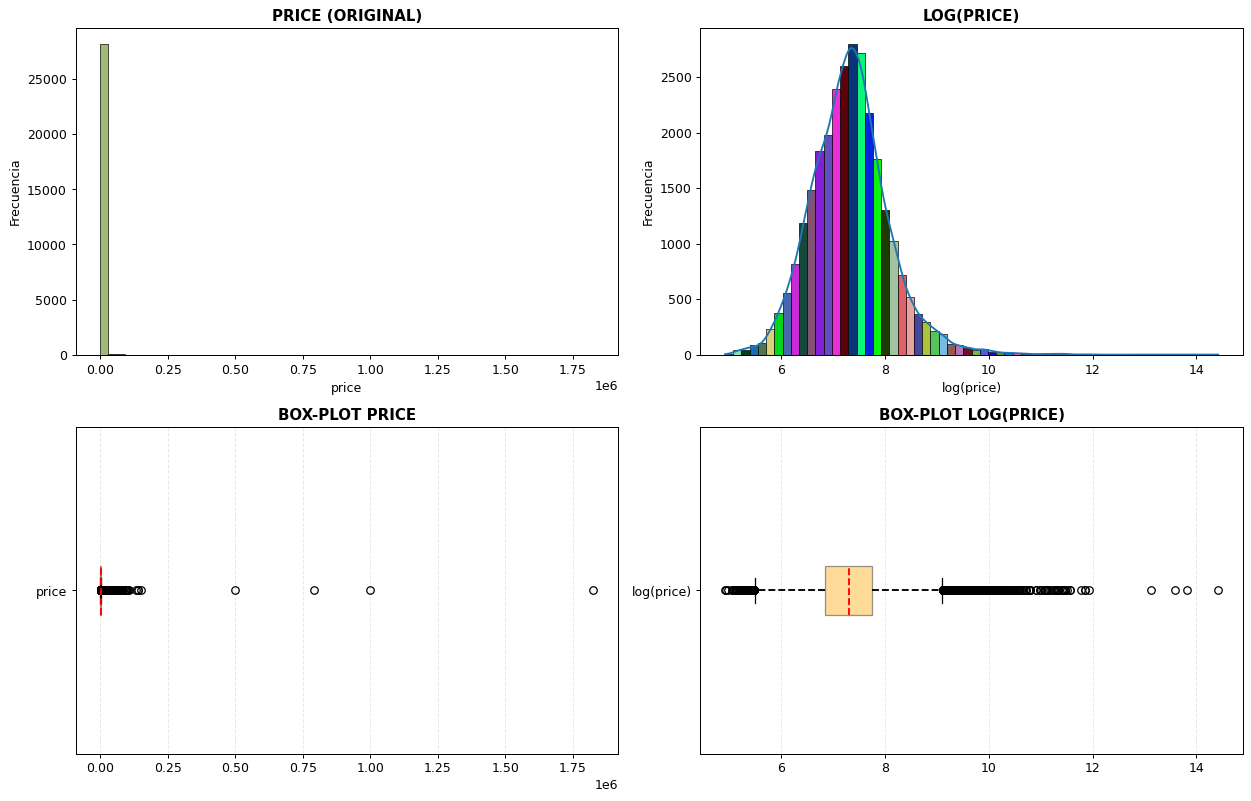

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

medianprops = dict(linestyle='dashed', linewidth=1.5, color='r') # firebrick
whiskerprops = dict(linestyle='--', linewidth=1.5)
boxprops = dict(facecolor='orange', alpha=0.4)

sns.histplot(df["price"], bins=60, ax=ax[0, 0])
patches = ax[0, 0].patches
for j in range(len(patches)):
    patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
ax[0, 0].set_title('PRICE (ORIGINAL)', fontweight='bold')
ax[0, 0].set_ylabel('Frecuencia')

sns.histplot(np.log(df["price"]), bins=60, kde=True, ax=ax[0, 1])
patches = ax[0, 1].patches
for j in range(len(patches)):
    patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
ax[0, 1].set_title('LOG(PRICE)', fontweight='bold')
ax[0, 1].set_xlabel('log(price)')
ax[0, 1].set_ylabel('Frecuencia')

for k, (serie, nombre) in enumerate([(df["price"], "price"), (np.log(df["price"]), "log(price)")]):
    ax[1, k].boxplot(serie, vert=False, medianprops=medianprops, whiskerprops=whiskerprops,
                     patch_artist=True, boxprops=boxprops)
    ax[1, k].xaxis.grid(True, linestyle='dashed', color='lightgrey', alpha=0.5)
    ax[1, k].set_yticklabels([nombre])
    ax[1, k].set_title('BOX-PLOT ' + nombre.upper(), fontweight='bold')

plt.tight_layout()
plt.show()

In [17]:
log_p = np.log(df["price"])
q1 = log_p.quantile(0.25)
q3 = log_p.quantile(0.75)
ric = q3 - q1
lim_inf_precio = np.exp(q1 - 1.5 * ric)
lim_sup_precio = np.exp(q3 + 1.5 * ric)
atipicos = df[(df["price"] < lim_inf_precio) | (df["price"] > lim_sup_precio)]
print("Límite inferior de precio:", round(lim_inf_precio, 2))
print("Límite superior de precio:", round(lim_sup_precio, 2))
print("Anuncios atípicos:", len(atipicos), "(", round(len(atipicos) / len(df) * 100, 2), "% )")
print("  por debajo:", (atipicos["price"] < lim_inf_precio).sum(), "| por encima:", (atipicos["price"] > lim_sup_precio).sum())
print("")
print("Precios más altos detectados:")
print(atipicos.sort_values("price", ascending=False)[["id", "neighbourhood", "room_type", "price", "number_of_reviews"]].head(8))

Límite inferior de precio: 241.82
Límite superior de precio: 9058.85
Anuncios atípicos: 698 ( 2.47 % )
  por debajo: 145 | por encima: 553

Precios más altos detectados:
                        id   neighbourhood        room_type      price  number_of_reviews
4509              38778769      Cuauhtémoc     Private room  1826199.0                227
11946   892676742760732948         Tlalpan     Private room  1000300.0                  3
23655  1603720147099182676  Miguel Hidalgo  Entire home/apt   790057.0                  0
10899   812373795418706059      Cuauhtémoc  Entire home/apt   500000.0                  6
9089    666513486864947875  Miguel Hidalgo  Entire home/apt   152220.0                  0
12103   901962391238044233         Tlalpan  Entire home/apt   141000.0                  0
7345              52691395      Cuauhtémoc  Entire home/apt   140654.0                 31
13024   963777841659697459      Cuauhtémoc  Entire home/apt   130669.0                  0

Registros: 27583
            Antes   Después
count    28281.00  27583.00
mean      2341.51   1845.83
std      14113.71   1366.90
min        137.00    243.00
25%        941.00    940.00
50%       1500.00   1490.00
75%       2328.00   2260.00
max    1826199.00   9034.00
Asimetría antes: 96.87 | después: 2.09

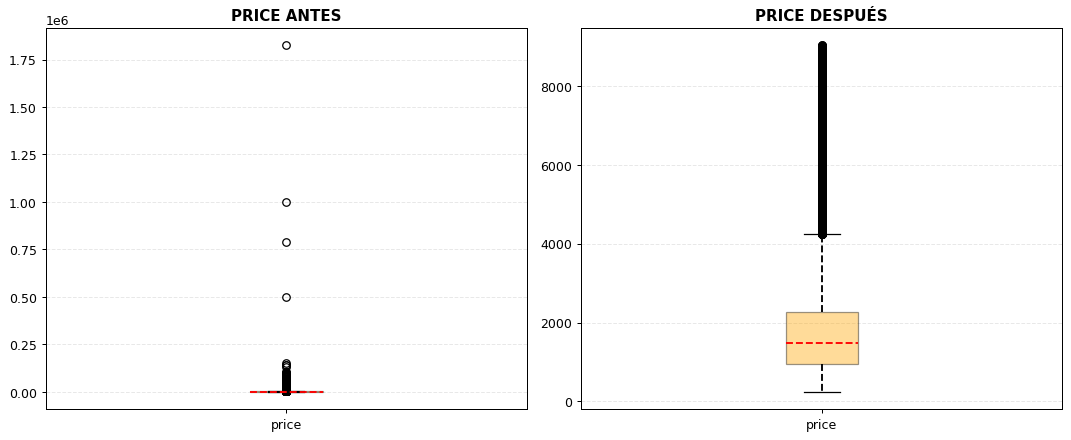

In [18]:
precio_antes = df["price"].copy()
df = df[(df["price"] >= lim_inf_precio) & (df["price"] <= lim_sup_precio)]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for k, (serie, titulo) in enumerate([(precio_antes, "PRICE ANTES"), (df["price"], "PRICE DESPUÉS")]):
    ax[k].boxplot(serie, medianprops=medianprops, whiskerprops=whiskerprops,
                  patch_artist=True, boxprops=boxprops)
    ax[k].yaxis.grid(True, linestyle='dashed', color='lightgrey', alpha=0.5)
    ax[k].set_xticklabels(['price'])
    ax[k].set_title(titulo, fontweight='bold')
plt.tight_layout()
plt.show()

print("Registros:", len(df))
print(round(pd.DataFrame({"Antes": precio_antes.describe(), "Después": df["price"].describe()}), 2))
print("Asimetría antes:", round(precio_antes.skew(), 2), "| después:", round(df["price"].skew(), 2))

**Criterios para variables numéricas:**

- **`price`** tiene una asimetría extrema (**96.9**) con valores de hasta \$1,826,199 por noche, lo que distorsiona la media y la desviación estándar. Aplicar el RIC directamente sobre el precio eliminaría a muchos alojamientos legítimos de gama alta, por lo que se aplica el **criterio de Tukey sobre `log(price)`** (cuya distribución es casi simétrica). Los límites resultantes son **\$241.82 – \$9,058.85 MXN por noche**, y se eliminaron **698 anuncios (2.47%)**, la mayoría con precios irreales (errores de captura o precios "bloqueados"). Tras el tratamiento la asimetría del precio baja de 96.9 a **2.09** y la mediana prácticamente no cambia.
- **`minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count` y `number_of_reviews_ltm`** también tienen colas largas, pero sus valores extremos son **legítimos** (estancias mensuales, anuncios muy populares, anfitriones profesionales con muchos anuncios). Eliminarlos haría perder información real del mercado, por lo que **se conservan** y se recomienda usar estadísticos robustos (mediana, RIC) o transformaciones logarítmicas en el análisis.
- **`availability_365`** está acotada entre 0 y 365 y no presenta atípicos.

### 2.5 Tratamiento de variables categóricas

In [19]:
for v in ["room_type", "neighbourhood"]:
    count = df[v].value_counts()
    print(pd.DataFrame({"Frecuencia": count, "%": round(df[v].value_counts(normalize=True) * 100, 2)}))
    print("Total: ", count.sum())
    print("-----------------------------")

                 Frecuencia      %
room_type                         
Entire home/apt       18463  66.94
Private room           8856  32.11
Shared room             202   0.73
Hotel room               62   0.22
Total:  27583
-----------------------------
                        Frecuencia      %
neighbourhood                            
Cuauhtémoc                   12820  46.48
Miguel Hidalgo                4275  15.50
Benito Juárez                 3166  11.48
Coyoacán                      2001   7.25
Venustiano Carranza           1005   3.64
Álvaro Obregón                 898   3.26
Tlalpan                        882   3.20
Iztacalco                      553   2.00
Gustavo A. Madero              541   1.96
Azcapotzalco                   385   1.40
Cuajimalpa de Morelos          354   1.28
Iztapalapa                     349   1.27
Xochimilco                     172   0.62
La Magdalena Contreras         116   0.42
Tláhuac                         42   0.15
Milpa Alta                      

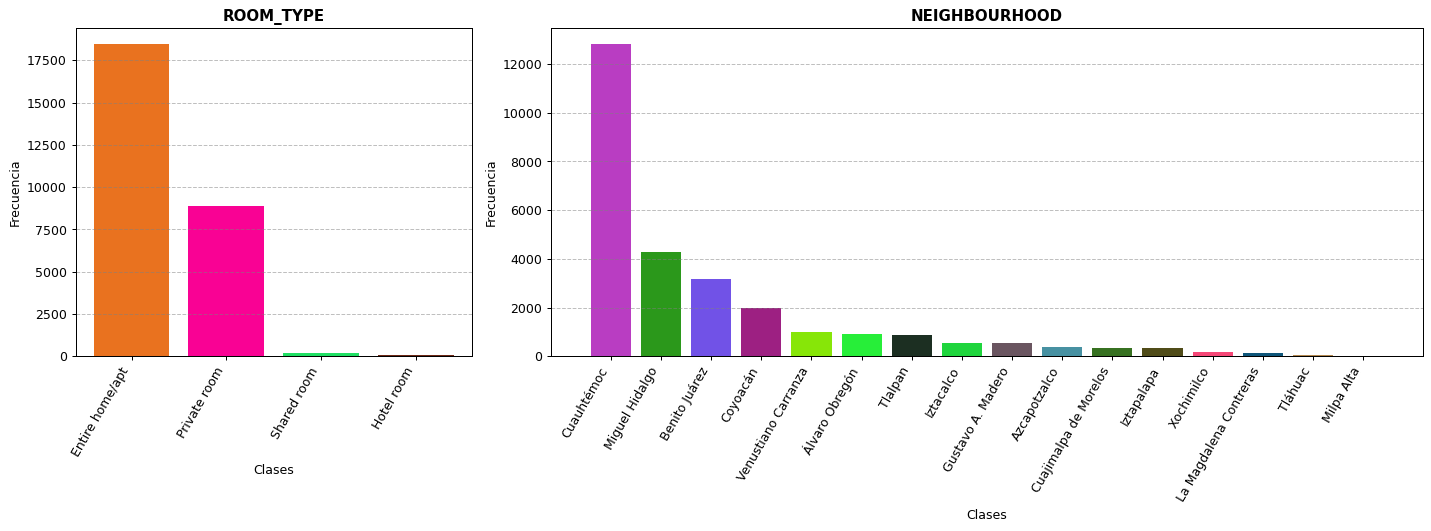

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 2.2]})

for i, v in enumerate(["room_type", "neighbourhood"]):
    count = df[v].value_counts()
    patches = ax[i].bar(count.index, count.values)
    for j in range(len(patches)):
        patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
    ax[i].yaxis.grid(color='grey', linestyle='dashed', alpha=0.5)
    ax[i].set_title(v.upper(), fontweight='bold')
    ax[i].set_xlabel('Clases')
    ax[i].set_ylabel('Frecuencia')
    ax[i].set_xticklabels(count.index, rotation=60, ha='right')

plt.tight_layout()
plt.show()

In [21]:
precio_tipo = df.pivot_table(index="room_type", values="price", aggfunc=["median", "mean", "count"])
precio_tipo.columns = ["Mediana", "Media", "N"]
print(round(precio_tipo.sort_values("Mediana", ascending=False), 2))
print("")
precio_alcaldia = df.pivot_table(index="neighbourhood", values="price", aggfunc=["median", "mean", "count"])
precio_alcaldia.columns = ["Mediana", "Media", "N"]
precio_alcaldia = precio_alcaldia.sort_values("Mediana", ascending=False)
print(round(precio_alcaldia, 2))

                 Mediana    Media      N
room_type                               
Entire home/apt   1800.0  2190.75  18463
Hotel room        1724.0  2890.81     62
Private room       849.0  1144.63   8856
Shared room        445.5   741.48    202

                        Mediana    Media      N
neighbourhood                                  
Miguel Hidalgo           1850.0  2287.83   4275
Cuajimalpa de Morelos    1789.0  2020.81    354
Cuauhtémoc               1673.0  2020.82  12820
Álvaro Obregón           1324.0  1598.57    898
Benito Juárez            1200.0  1479.19   3166
Coyoacán                 1190.0  1548.42   2001
Iztacalco                1160.0  1328.89    553
Xochimilco               1044.5  1548.30    172
La Magdalena Contreras   1019.5  1568.72    116
Tlalpan                  1000.0  1594.41    882
Venustiano Carranza       999.0  1242.09   1005
Azcapotzalco              921.0  1169.70    385
Gustavo A. Madero         838.0  1062.69    541
Iztapalapa                827.0  

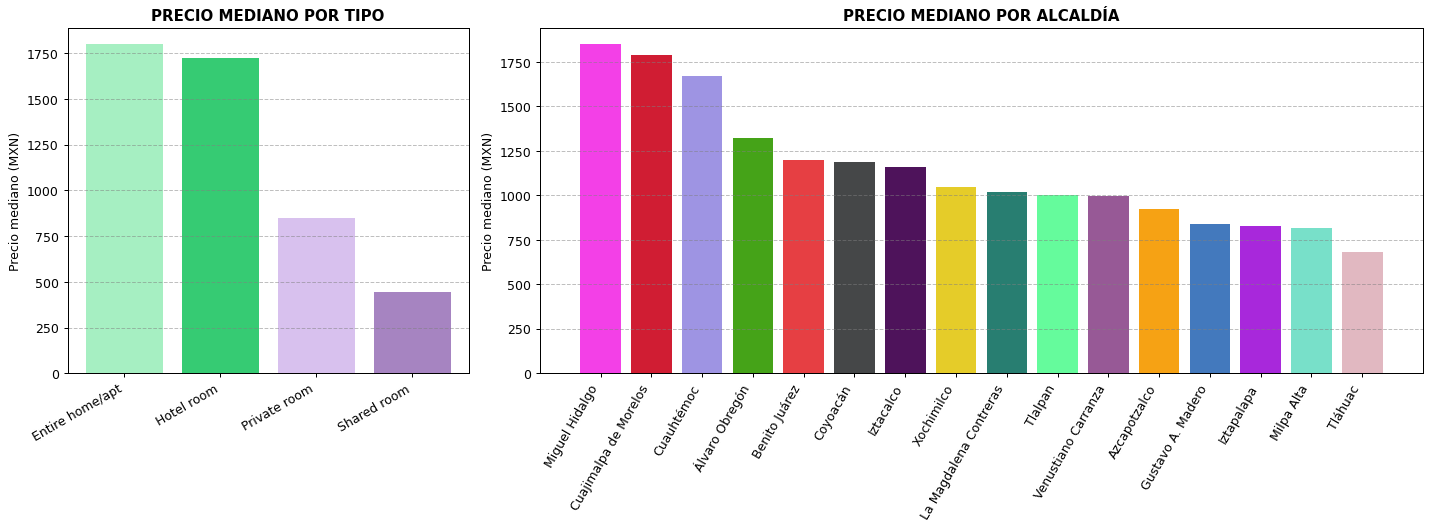

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 2.2]})

pt = precio_tipo.sort_values("Mediana", ascending=False)
patches = ax[0].bar(pt.index, pt["Mediana"])
for j in range(len(patches)):
    patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
ax[0].set_title('PRECIO MEDIANO POR TIPO', fontweight='bold')
ax[0].set_ylabel('Precio mediano (MXN)')
ax[0].set_xticklabels(pt.index, rotation=30, ha='right')
ax[0].yaxis.grid(color='grey', linestyle='dashed', alpha=0.5)

patches = ax[1].bar(precio_alcaldia.index, precio_alcaldia["Mediana"])
for j in range(len(patches)):
    patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
ax[1].set_title('PRECIO MEDIANO POR ALCALDÍA', fontweight='bold')
ax[1].set_ylabel('Precio mediano (MXN)')
ax[1].set_xticklabels(precio_alcaldia.index, rotation=60, ha='right')
ax[1].yaxis.grid(color='grey', linestyle='dashed', alpha=0.5)

plt.tight_layout()
plt.show()

**Interpretación de las variables categóricas:**

- **`room_type`:** predominan los **alojamientos completos** (`Entire home/apt`: 66.9%), seguidos de habitaciones privadas (32.1%). Las habitaciones compartidas (202) y de hotel (62) son categorías minoritarias (< 1.5% en conjunto); se conservan porque representan segmentos reales del mercado, pero cualquier conclusión sobre ellas debe tomarse con cautela por su tamaño de muestra.
- El precio mediano de un alojamiento completo (\$1,800) es aproximadamente **2.1 veces** el de una habitación privada (\$849), por lo que `room_type` es potencialmente una variable muy relevante para explicar el precio.
- **`neighbourhood`:** la oferta está muy concentrada: **46.5%** de los anuncios están en Cuauhtémoc y las 3 primeras alcaldías (Cuauhtémoc, Miguel Hidalgo, Benito Juárez) suman el **73.5%**. Las alcaldías con mayor precio mediano son Miguel Hidalgo, Cuajimalpa de Morelos, Cuauhtémoc, mientras que las más económicas son Iztapalapa, Milpa Alta, Tláhuac. Alcaldías como Milpa Alta o Tláhuac tienen muy pocos registros, lo que se considerará en la interpretación.

### 2.6 Transformación de datos (codificación)

In [23]:
# 1) Nuevas variables numéricas
df["log_price"] = np.log(df["price"])
df["dias_desde_ultima_resena"] = (fecha_corte - df["last_review"]).dt.days
max_dias = df["dias_desde_ultima_resena"].max()
# anuncios sin reseña: se les asigna el máximo observado (la "antigüedad" más alta) + indicador tiene_resenas
df["dias_desde_ultima_resena"] = df["dias_desde_ultima_resena"].fillna(max_dias).astype(int)

# 2) Discretización de minimum_nights en tipo de estancia
df["tipo_estancia"] = pd.cut(df["minimum_nights"], bins=[0, 7, 29, 365],
                             labels=["Corta (1-7)", "Media (8-29)", "Larga (30+)"])
print(df["tipo_estancia"].value_counts())
print("")
print(round(df[["price", "log_price", "dias_desde_ultima_resena"]].describe(), 2))

tipo_estancia
Corta (1-7)     26999
Media (8-29)      374
Larga (30+)       210
Name: count, dtype: int64

          price  log_price  dias_desde_ultima_resena
count  27583.00   27583.00                  27583.00
mean    1845.83       7.30                    628.36
std     1366.90       0.66                   1368.42
min      243.00       5.49                      0.00
25%      940.00       6.85                     15.00
50%     1490.00       7.31                     35.00
75%     2260.00       7.72                    194.00
max     9034.00       9.11                   4250.00

In [24]:
# 3) Codificación one-hot de variables categóricas nominales
df_cod = pd.get_dummies(df.drop(columns=["last_review"]),
                        columns=["room_type", "neighbourhood", "tipo_estancia"],
                        prefix=["room", "alc", "estancia"], dtype=int)
print("Dimensiones base limpia (df):", df.shape)
print("Dimensiones base codificada (df_cod):", df_cod.shape)
print("")
print(df_cod.columns.tolist())
print("")
print(df_cod.head(3).T.head(20))

Dimensiones base limpia (df): (27583, 18)
Dimensiones base codificada (df_cod): (27583, 37)

['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'tiene_resenas', 'log_price', 'dias_desde_ultima_resena', 'room_Entire home/apt', 'room_Hotel room', 'room_Private room', 'room_Shared room', 'alc_Azcapotzalco', 'alc_Benito Juárez', 'alc_Coyoacán', 'alc_Cuajimalpa de Morelos', 'alc_Cuauhtémoc', 'alc_Gustavo A. Madero', 'alc_Iztacalco', 'alc_Iztapalapa', 'alc_La Magdalena Contreras', 'alc_Miguel Hidalgo', 'alc_Milpa Alta', 'alc_Tlalpan', 'alc_Tláhuac', 'alc_Venustiano Carranza', 'alc_Xochimilco', 'alc_Álvaro Obregón', 'estancia_Corta (1-7)', 'estancia_Media (8-29)', 'estancia_Larga (30+)']

                                            0              2              3
id                               35797.000000   56074.000000   66055.000000
host_id          

**Transformaciones realizadas:**

| Transformación | Variable resultante | Justificación |
| :-- | :-- | :-- |
| Logaritmo natural del precio | `log_price` | Corrige la asimetría del precio (asimetría ≈ 0.09); útil para modelos estadísticos que suponen normalidad |
| Fecha → número de días | `dias_desde_ultima_resena` | Convierte `last_review` (fecha) en una medida numérica de actividad reciente respecto a la fecha de corte (2026-09-25); a los anuncios sin reseña se les asigna el máximo (4,250 días) y se identifican con `tiene_resenas = 0` |
| Indicador binario | `tiene_resenas` | Conserva la información del nulo estructural |
| Discretización | `tipo_estancia` | Agrupa `minimum_nights` en estancias corta (1-7), media (8-29) y larga (30+), segmentos con comportamientos distintos |
| *One-hot encoding* | `room_*`, `alc_*`, `estancia_*` | `room_type`, `neighbourhood` y `tipo_estancia` son nominales (sin orden), por lo que se codifican en variables binarias 0/1 en lugar de códigos numéricos que impondrían un orden falso |

La base codificada `df_cod` queda con **27,583 registros y 37 columnas**, todas numéricas.

## 3. Análisis y Visualización

### Hipótesis
El precio por noche de los alojamientos de Airbnb en la CDMX depende principalmente del **tipo de alojamiento** y de la **alcaldía** (zonas céntricas como Cuauhtémoc y Miguel Hidalgo son más caras), mientras que las variables de actividad (número de reseñas, disponibilidad, noches mínimas) tienen una relación débil con el precio.

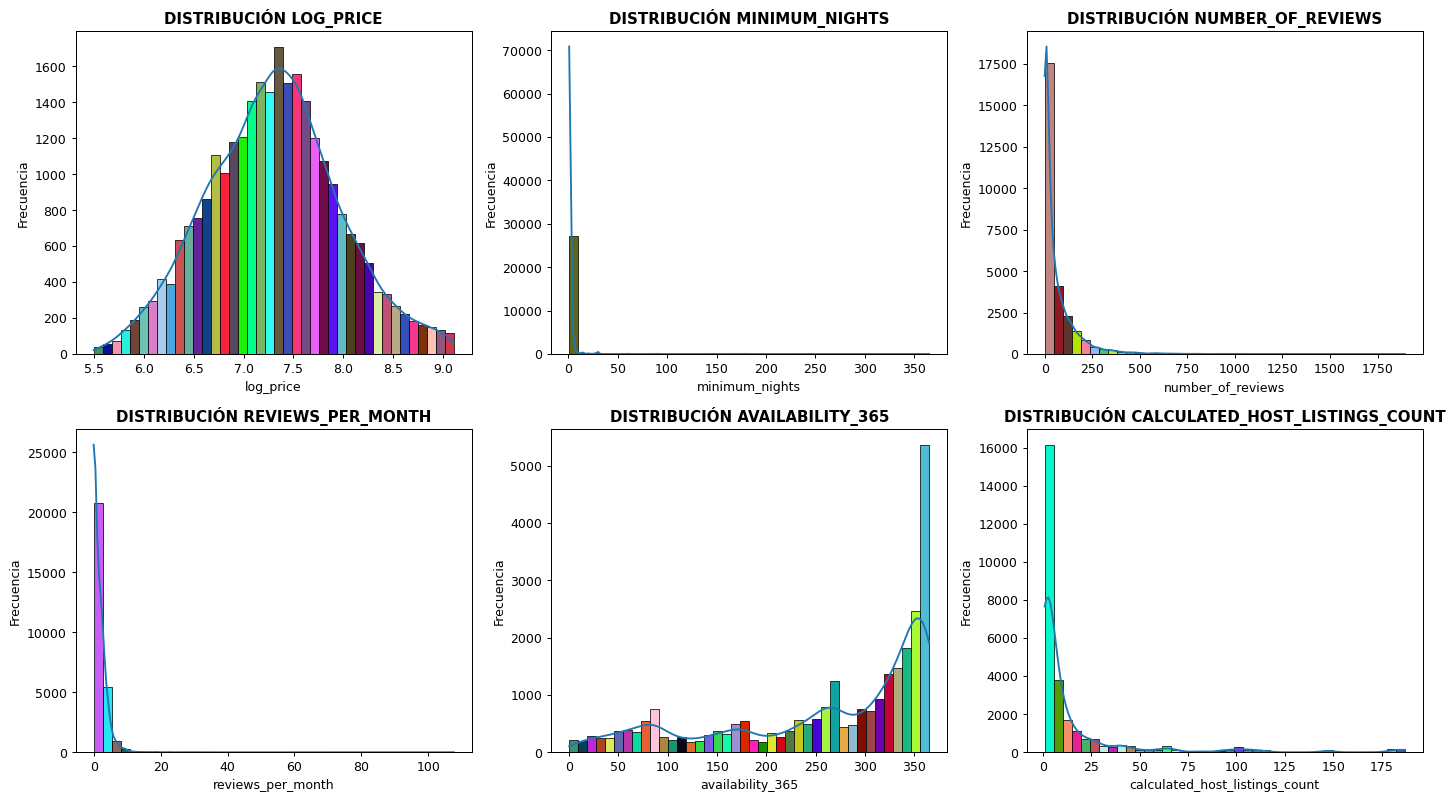

In [25]:
vars_hist = ["log_price", "minimum_nights", "number_of_reviews", "reviews_per_month",
             "availability_365", "calculated_host_listings_count"]
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
ax = ax.flatten()
for i, v in enumerate(vars_hist):
    sns.histplot(df[v], bins=40, kde=True, ax=ax[i])
    patches = ax[i].patches
    for j in range(len(patches)):
        patches[j].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
    ax[i].set_title('DISTRIBUCIÓN ' + v.upper(), fontweight='bold')
    ax[i].set_xlabel(v)
    ax[i].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

longitude                        -0.226
availability_365                 -0.073
minimum_nights                   -0.028
number_of_reviews                -0.018
reviews_per_month                -0.009
number_of_reviews_ltm            -0.008
dias_desde_ultima_resena          0.026
calculated_host_listings_count    0.086
latitude                          0.102
Name: price, dtype: float64

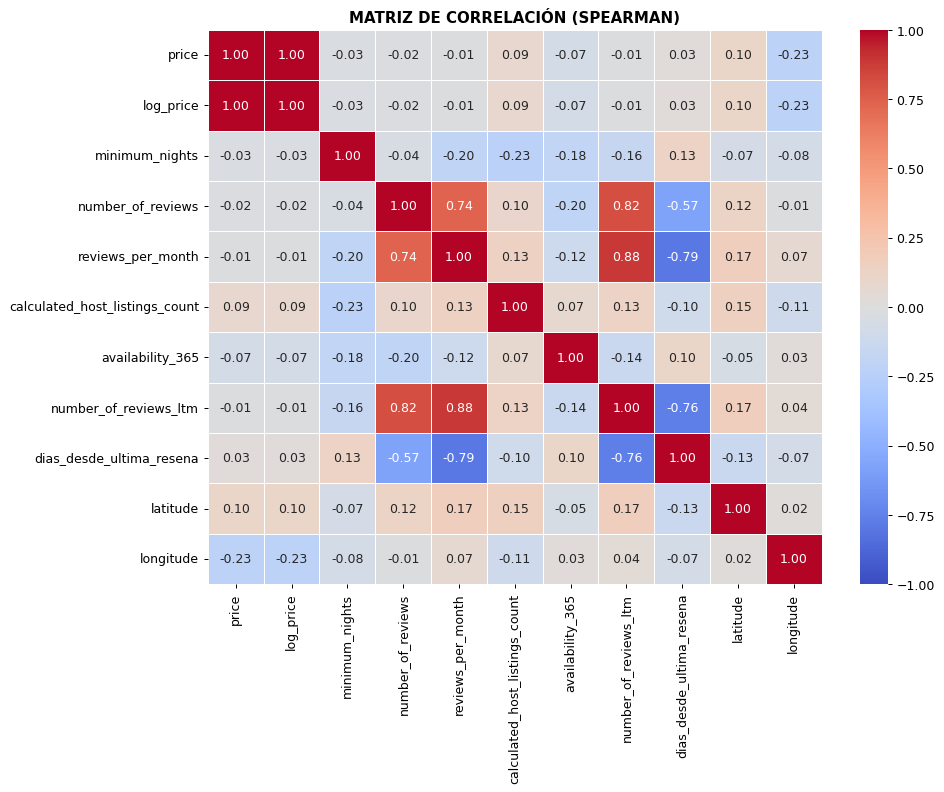

In [26]:
vars_corr = ["price", "log_price", "minimum_nights", "number_of_reviews", "reviews_per_month",
             "calculated_host_listings_count", "availability_365", "number_of_reviews_ltm",
             "dias_desde_ultima_resena", "latitude", "longitude"]
corr = df[vars_corr].corr(method="spearman")
print(round(corr["price"].drop(["price", "log_price"]).sort_values(), 3))

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title('MATRIZ DE CORRELACIÓN (SPEARMAN)', fontweight='bold')
plt.show()

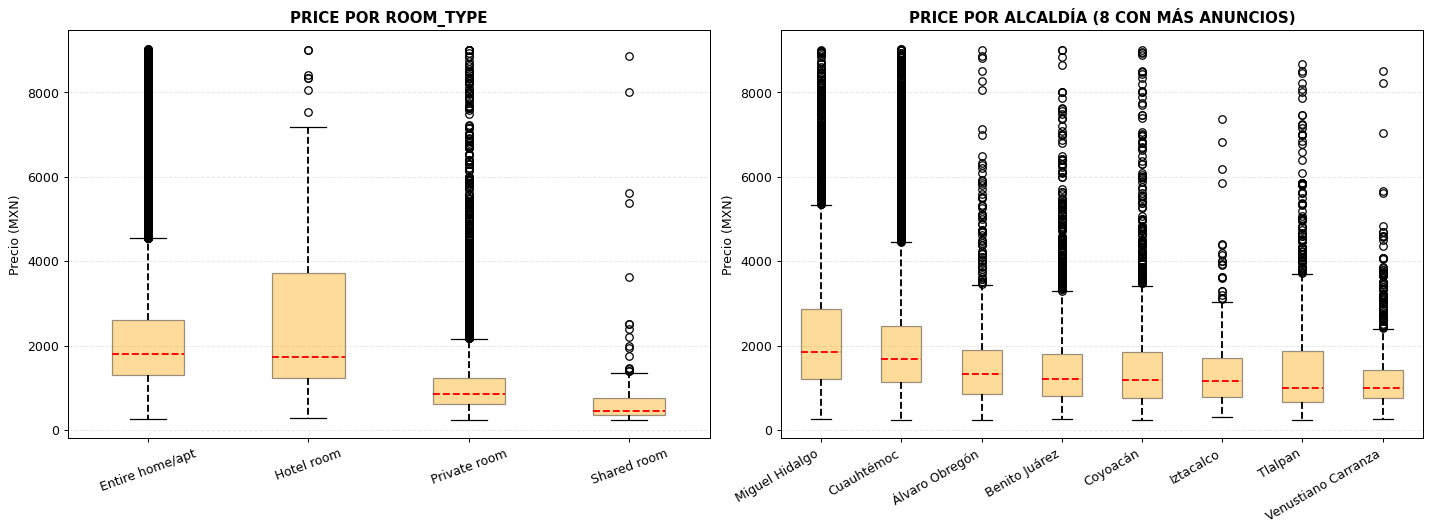

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

orden = df.groupby("room_type")["price"].median().sort_values(ascending=False).index
datos = [df.loc[df["room_type"] == t, "price"] for t in orden]
ax[0].boxplot(datos, medianprops=medianprops, whiskerprops=whiskerprops,
              patch_artist=True, boxprops=boxprops)
ax[0].set_xticklabels(orden, rotation=20)
ax[0].yaxis.grid(True, linestyle='dashed', color='lightgrey', alpha=0.5)
ax[0].set_title('PRICE POR ROOM_TYPE', fontweight='bold')
ax[0].set_ylabel('Precio (MXN)')

top = df["neighbourhood"].value_counts().index[:8]
orden2 = df[df["neighbourhood"].isin(top)].groupby("neighbourhood")["price"].median().sort_values(ascending=False).index
datos2 = [df.loc[df["neighbourhood"] == a, "price"] for a in orden2]
ax[1].boxplot(datos2, medianprops=medianprops, whiskerprops=whiskerprops,
              patch_artist=True, boxprops=boxprops)
ax[1].set_xticklabels(orden2, rotation=30, ha='right')
ax[1].yaxis.grid(True, linestyle='dashed', color='lightgrey', alpha=0.5)
ax[1].set_title('PRICE POR ALCALDÍA (8 CON MÁS ANUNCIOS)', fontweight='bold')
ax[1].set_ylabel('Precio (MXN)')

plt.tight_layout()
plt.show()

Spearman number_of_reviews vs price: -0.018

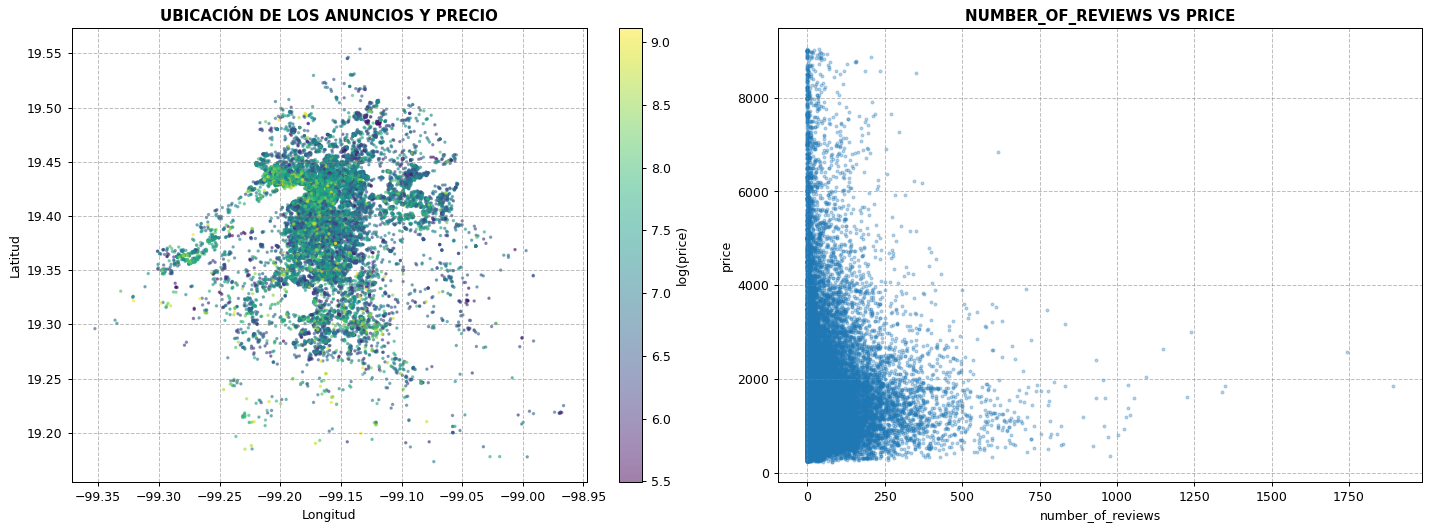

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

mapa = ax[0].scatter(df["longitude"], df["latitude"], c=df["log_price"], cmap="viridis", s=3, alpha=0.5)
plt.colorbar(mapa, ax=ax[0], label="log(price)")
ax[0].grid(color='grey', linestyle='dashed', alpha=0.5)
ax[0].set_title('UBICACIÓN DE LOS ANUNCIOS Y PRECIO', fontweight='bold')
ax[0].set_xlabel('Longitud')
ax[0].set_ylabel('Latitud')

ax[1].scatter(df["number_of_reviews"], df["price"], alpha=0.3, s=5)
ax[1].grid(color='grey', linestyle='dashed', alpha=0.5)
ax[1].set_title('NUMBER_OF_REVIEWS VS PRICE', fontweight='bold')
ax[1].set_xlabel('number_of_reviews')
ax[1].set_ylabel('price')

plt.tight_layout()
plt.show()

print("Spearman number_of_reviews vs price:", round(stats.spearmanr(df["number_of_reviews"], df["price"])[0], 3))

**Interpretación de los análisis exploratorios:**

- **Distribuciones:** `log_price` presenta una forma aproximadamente acampanada, lo que confirma que la transformación logarítmica es adecuada. `minimum_nights`, `number_of_reviews`, `reviews_per_month` y `calculated_host_listings_count` tienen asimetría positiva fuerte (la mayoría de los anuncios tiene valores bajos y unos pocos valores muy altos). `availability_365` está cargada hacia valores altos: la mayoría de los anuncios está disponible gran parte del año.
- **Correlaciones (Spearman, robusta a asimetría y atípicos):** ninguna variable numérica tiene una correlación fuerte con el precio; las mayores en valor absoluto son `longitude` (ρ = -0.23) y `latitude` (ρ = 0.10). Las variables de reseñas están muy correlacionadas entre sí (`number_of_reviews`, `reviews_per_month`, `number_of_reviews_ltm`), por lo que en un modelo conviene no usar todas a la vez (multicolinealidad).
- **Precio por tipo y alcaldía:** las cajas muestran diferencias claras: los alojamientos completos tienen una mediana mucho mayor que las habitaciones privadas y compartidas; y Miguel Hidalgo/Cuauhtémoc concentran precios más altos que alcaldías periféricas. Esto **apoya la hipótesis** de que el tipo de alojamiento y la ubicación son los factores más relevantes.
- **Mapa:** los anuncios se concentran en el corredor centro-poniente (Centro, Roma, Condesa, Polanco), donde predominan colores de precio más alto; en la periferia la densidad de anuncios es baja.
- **Reseñas vs precio:** la nube de puntos no muestra una tendencia (ρ ≈ -0.02): tener más reseñas no implica un precio mayor, lo cual también es consistente con la hipótesis.

## 4. Validación de la base de datos final

In [29]:
validacion = {
    "Sin nulos en variables de análisis (excepto last_review estructural)": df.drop(columns=["last_review"]).isnull().sum().sum() == 0,
    "last_review nulo solo cuando no hay reseñas": (df["last_review"].isna() == (df["number_of_reviews"] == 0)).all(),
    "Base codificada sin nulos": df_cod.isnull().sum().sum() == 0,
    "Sin duplicados": df.duplicated(subset=[c for c in df.columns if c != "id"]).sum() == 0,
    "id único": df["id"].is_unique,
    "price dentro de límites": df["price"].between(lim_inf_precio, lim_sup_precio).all(),
    "minimum_nights en [1, 365]": df["minimum_nights"].between(1, 365).all(),
    "availability_365 en [0, 365]": df["availability_365"].between(0, 365).all(),
    "reviews_ltm <= reviews": (df["number_of_reviews_ltm"] <= df["number_of_reviews"]).all(),
    "Coordenadas dentro de CDMX": (df["latitude"].between(19.0, 19.6) & df["longitude"].between(-99.4, -98.9)).all(),
    "16 alcaldías presentes": df["neighbourhood"].nunique() == 16,
    "4 tipos de alojamiento presentes": df["room_type"].nunique() == 4,
    "Base codificada 100% numérica": all(pd.api.types.is_numeric_dtype(t) for t in df_cod.dtypes),
}
print(pd.DataFrame.from_dict(validacion, orient="index", columns=["Cumple"]).to_string())
print("")
print(df.info())

                                                                      Cumple
Sin nulos en variables de análisis (excepto last_review estructural)    True
last_review nulo solo cuando no hay reseñas                             True
Base codificada sin nulos                                               True
Sin duplicados                                                          True
id único                                                                True
price dentro de límites                                                 True
minimum_nights en [1, 365]                                              True
availability_365 en [0, 365]                                            True
reviews_ltm <= reviews                                                  True
Coordenadas dentro de CDMX                                              True
16 alcaldías presentes                                                  True
4 tipos de alojamiento presentes                                        True

In [30]:
rep = []
for v in ["room_type", "neighbourhood"]:
    p0 = dataSet[v].value_counts(normalize=True) * 100
    p1 = df[v].value_counts(normalize=True) * 100
    t = pd.DataFrame({"% Original": p0, "% Final": p1})
    t["Diferencia (pp)"] = t["% Final"] - t["% Original"]
    t.index = [v + ": " + str(i) for i in t.index]
    rep.append(t)
representatividad = pd.concat(rep)
print(round(representatividad, 2).to_string())
print("")
print("Máxima diferencia absoluta (pp):", round(representatividad["Diferencia (pp)"].abs().max(), 2))
print("Registros conservados:", len(df), "de", len(dataSet), "(", round(len(df) / len(dataSet) * 100, 2), "% )")

                                       % Original  % Final  Diferencia (pp)
room_type: Entire home/apt                  66.78    66.94             0.15
room_type: Private room                     32.07    32.11             0.04
room_type: Shared room                       0.90     0.73            -0.17
room_type: Hotel room                        0.25     0.22            -0.02
neighbourhood: Azcapotzalco                  1.35     1.40             0.05
neighbourhood: Benito Juárez                11.40    11.48             0.08
neighbourhood: Coyoacán                      7.25     7.25             0.00
neighbourhood: Cuajimalpa de Morelos         1.32     1.28            -0.04
neighbourhood: Cuauhtémoc                   46.49    46.48            -0.02
neighbourhood: Gustavo A. Madero             1.89     1.96             0.07
neighbourhood: Iztacalco                     1.89     2.00             0.11
neighbourhood: Iztapalapa                    1.25     1.27             0.02
neighbourhoo

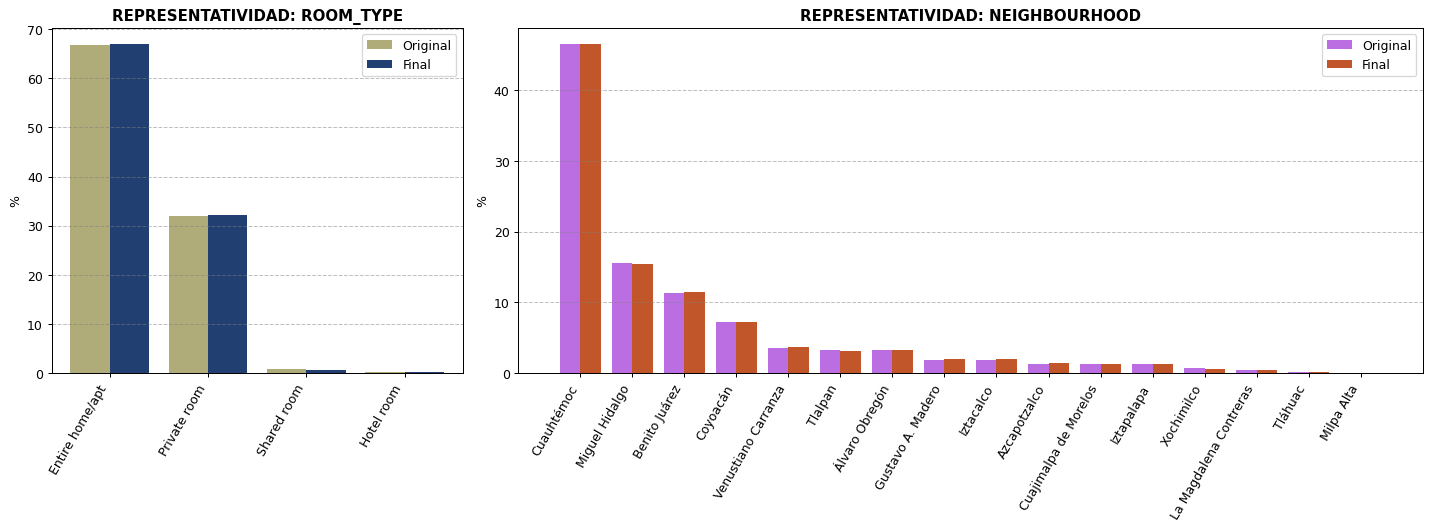

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 2.2]})
for i, v in enumerate(["room_type", "neighbourhood"]):
    p0 = dataSet[v].value_counts(normalize=True) * 100
    p1 = (df[v].value_counts(normalize=True) * 100).reindex(p0.index)
    x = np.arange(len(p0))
    ax[i].bar(x - 0.2, p0.values, width=0.4, label="Original", color="#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
    ax[i].bar(x + 0.2, p1.values, width=0.4, label="Final", color="#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
    ax[i].set_xticks(x)
    ax[i].set_xticklabels(p0.index, rotation=60, ha='right')
    ax[i].yaxis.grid(color='grey', linestyle='dashed', alpha=0.5)
    ax[i].set_title('REPRESENTATIVIDAD: ' + v.upper(), fontweight='bold')
    ax[i].set_ylabel('%')
    ax[i].legend()
plt.tight_layout()
plt.show()

In [32]:
cols_comp = ["price", "minimum_nights", "number_of_reviews", "reviews_per_month", "availability_365"]
print(round(dataSet[cols_comp].describe(), 2))
print("")
print(round(filter_data[cols_comp].describe(), 2))
print("")
print(round(df[cols_comp].describe(), 2))

            price  minimum_nights  number_of_reviews  reviews_per_month  availability_365
count    28360.00        30467.00           30468.00           26385.00          30468.00
mean      2339.96            2.92              58.92               2.01            247.83
std      14094.18           16.03              95.34               2.28            119.10
min        137.00            1.00               0.00               0.01              0.00
25%        942.00            1.00               4.00               0.57            163.00
50%       1500.00            1.00              22.00               1.47            296.00
75%       2327.00            2.00              75.00               2.79            349.00
max    1826199.00          600.00            1893.00             107.56            365.00

            price  minimum_nights  number_of_reviews  reviews_per_month  availability_365
count    28360.00        28359.00           28360.00           24778.00          28360.00
mean     

**Validación:**

- **Completa:** todas las reglas de validación se cumplen (`True`). La base limpia no tiene nulos salvo `last_review`, cuyo vacío es estructural (anuncios sin reseñas) y está representado por `tiene_resenas` y `dias_desde_ultima_resena`; la base codificada no tiene ningún nulo y es 100% numérica.
- **Consistente:** no hay duplicados, los rangos de todas las variables son válidos y se respetan las reglas lógicas entre columnas.
- **Representativa:** se conservó el **90.53%** de los registros (27,583 de 30,468) y la diferencia máxima entre las proporciones originales y finales de `room_type` y `neighbourhood` es de solo **0.17 puntos porcentuales**, por lo que la base final mantiene la estructura del mercado original. La comparación de `describe()` muestra que mediana y cuartiles se mantienen, mientras que la media y desviación del precio dejan de estar distorsionadas por valores irreales.
- **Relevante:** se conservaron las variables con potencial explicativo para el análisis estadístico del precio: tipo de alojamiento, alcaldía, coordenadas, condiciones de reserva y actividad de reseñas, más las variables derivadas.

## 5. Archivo final de la Base de Datos

In [33]:
df.to_csv("listings_limpio.csv", index=False)
df_cod.to_csv("listings_final_codificado.csv", index=False)

print("Archivo 'listings_limpio.csv' guardado:", df.shape)
print("Archivo 'listings_final_codificado.csv' guardado:", df_cod.shape)
print("")
print("Resumen del proceso:")
print("  Registros originales:                 ", len(dataSet))
print("  - Sin precio (anuncios inactivos):    ", dataSet["price"].isna().sum())
print("  - Duplicados:                         ", n_dup)
print("  - Precios atípicos (RIC sobre log):   ", len(atipicos))
print("  = Registros finales:                  ", len(df))

Archivo 'listings_limpio.csv' guardado: (27583, 18)
Archivo 'listings_final_codificado.csv' guardado: (27583, 37)

Resumen del proceso:
  Registros originales:                  30468
  - Sin precio (anuncios inactivos):     2108
  - Duplicados:                          79
  - Precios atípicos (RIC sobre log):    698
  = Registros finales:                   27583

### Conclusiones

1. La base original (30,468 × 19) presentaba dos columnas totalmente vacías, nulos en la variable objetivo (`price`), nulos estructurales en las variables de reseñas, anuncios duplicados y precios extremos que distorsionaban la estadística descriptiva.
2. Con la metodología aplicada se obtuvo una base **limpia, completa, consistente y representativa** de **27,583 anuncios** (90.53% de la original), disponible en dos versiones: `listings_limpio.csv` (legible, 18 columnas) y `listings_final_codificado.csv` (lista para modelado, 37 columnas numéricas).
3. El análisis exploratorio indica que el **tipo de alojamiento** y la **ubicación (alcaldía/coordenadas)** son las variables con mayor relación con el precio, mientras que las variables de actividad (reseñas, disponibilidad, noches mínimas) tienen relaciones débiles, lo que apoya la hipótesis planteada.
4. Para el análisis estadístico posterior se recomienda trabajar con `log_price`, estadísticos robustos y evitar usar simultáneamente las variables de reseñas por su alta correlación entre sí.